In [4]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
import matplotlib.pyplot as plt


In [5]:
import os
import shutil
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from PIL import ImageFile

# Allow loading of truncated images instead of crashing
ImageFile.LOAD_TRUNCATED_IMAGES = True
# 🔹 Original dataset path
RAW_DATASET_PATH = "C:\\face\\dataset"

# 🔹 New processed dataset path
PROCESSED_PATH = "./processed_dataset"

splits = ["train", "test", "val"]
classes = ["live", "spoof"]


if not os.path.exists(PROCESSED_PATH):
    splits = ["train", "test", "val"]
    classes = ["live", "spoof"]

    # ✅ Flatten the directory so ImageFolder works
    for split in splits:
        for cls in classes:
            os.makedirs(os.path.join(PROCESSED_PATH, split, cls), exist_ok=True)

            src_dir = os.path.join(RAW_DATASET_PATH, split)
            for person_id in os.listdir(src_dir):
                cls_dir = os.path.join(src_dir, person_id, cls)
                if os.path.exists(cls_dir):
                    for img in os.listdir(cls_dir):
                        src_img = os.path.join(cls_dir, img)
                        dst_img = os.path.join(PROCESSED_PATH, split, cls, f"{person_id}_{img}")
                        shutil.copy(src_img, dst_img)

    print("✅ Dataset flattened successfully!")
else:
    print("✅ Processed dataset already exists. Skipping processing step.")

# 🔹 Define transforms
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5])
])

# 🔹 Load datasets
train_dataset = datasets.ImageFolder(os.path.join(PROCESSED_PATH, "train"), transform=transform)
val_dataset   = datasets.ImageFolder(os.path.join(PROCESSED_PATH, "val"),   transform=transform)
test_dataset  = datasets.ImageFolder(os.path.join(PROCESSED_PATH, "test"),  transform=transform)


train_dataset = datasets.ImageFolder(
    root="./processed_dataset/train",
    transform=transform
)

test_dataset = datasets.ImageFolder(
    root="./processed_dataset/test",
    transform=transform
)
val_dataset = datasets.ImageFolder(
    root="./processed_dataset/val",
    transform=transform
)
# # 🔹 Create dataloaders
# train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
# val_loader   = DataLoader(val_dataset, batch_size=32, shuffle=False)
# test_loader  = DataLoader(test_dataset, batch_size=32, shuffle=False)

# print(f"Train set size: {len(train_dataset)}")
# print(f"Val set size:   {len(val_dataset)}")
# print(f"Test set size:  {len(test_dataset)}")


✅ Processed dataset already exists. Skipping processing step.


In [16]:
# from PIL import Image
# import os

# def check_images(folder):
#     bad_files = []
#     for root, _, files in os.walk(folder):
#         for f in files:
#             path = os.path.join(root, f)
#             try:
#                 img = Image.open(path)
#                 img.verify()  # verify integrity
#             except:
#                 bad_files.append(path)
#                 print("Corrupted:", path)
#                 os.remove(path)  # optional: remove it
#     print(f"Found {len(bad_files)} bad files.")

# check_images("./processed_dataset/train")
# check_images("./processed_dataset/test")


In [6]:
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, num_workers=4, pin_memory=True, prefetch_factor=2)
val_loader   = DataLoader(val_dataset, batch_size=64, shuffle=False, num_workers=4, pin_memory=True, prefetch_factor=2)
test_loader  = DataLoader(test_dataset, batch_size=64, shuffle=False, num_workers=4, pin_memory=True, prefetch_factor=2)

print(f"Train set size: {len(train_dataset)}")
print(f"Val set size:   {len(val_dataset)}")
print(f"Test set size:  {len(test_dataset)}")

Train set size: 297526
Val set size:   196875
Test set size:  67170


In [18]:

# from torchvision.models import efficientnet_b0

# model = efficientnet_b0(weights="IMAGENET1K_V1")
# model.classifier[1] = nn.Linear(model.classifier[1].in_features, 2)
# model = model.to(device)
# print(model)
# print(device)


In [7]:

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = models.mobilenet_v2(pretrained=True)

# Replace last layer (1000 → 2 classes)

# model.classifier[1] = nn.Linear(model.last_channel, 2)

for param in model.features.parameters():
    param.requires_grad = False


model.classifier = nn.Sequential(
    nn.Dropout(0.5),  # Add Dropout with 50% probability
    nn.Linear(model.last_channel, 2)  # Final fully connected layer
)

model = model.to(device)
print(model)
print(device)


C:\Users\user\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\user\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


MobileNetV2(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
    )
    (2): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (1): BatchNorm2d(96, eps=

In [8]:

criterion = nn.CrossEntropyLoss()
# optimizer = optim.Adam(model.parameters(), lr=0.001) -- Learning Rate Tuning, Regularization
optimizer = optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-4)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', patience=3, factor=0.5)


import os
os.environ["CUDA_LAUNCH_BLOCKING"] = "1"


In [9]:

from tqdm import tqdm
from torch.amp import GradScaler, autocast

def train_model(model, criterion, optimizer, train_loader, test_loader, scheduler=None, num_epochs=10, patience=5, checkpoint_path="face_4.pth", resume=False):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)

    best_acc = 0.0
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    patience_counter = 0
    scaler = GradScaler("cuda")# Initialize GradScaler for mixed precision training

    # Resume checkpoint if needed
    if resume and os.path.exists(checkpoint_path):
        checkpoint = torch.load(checkpoint_path)
        model.load_state_dict(checkpoint["model_state"])
        optimizer.load_state_dict(checkpoint["optimizer_state"])
        if scheduler and checkpoint["scheduler_state"]:
            scheduler.load_state_dict(checkpoint["scheduler_state"])
        best_acc = checkpoint["best_acc"]
        start_epoch = checkpoint["epoch"] + 1
    else:
        start_epoch = 0
    print(f"🔄 Resumed from checkpoint with best acc: {best_acc:.4f}")

    for epoch in range(start_epoch, num_epochs):
        print(f"\nEpoch {epoch+1}/{num_epochs}")
        print("-" * 30)

        # ---------- Training ----------
        model.train()
        running_loss, running_corrects = 0.0, 0

        train_bar = tqdm(train_loader, desc="[TRAIN]", leave=False)
        for inputs, labels in train_bar:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()

            with autocast("cuda"):  # Enable mixed precision
                outputs = model(inputs)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()  # Scale the loss for mixed precision
            scaler.step(optimizer)         # Step the optimizer
            scaler.update()                # Update the scaler

            _, preds = torch.max(outputs, 1)
            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(preds == labels.data)

            train_bar.set_postfix(loss=loss.item())

        epoch_loss = running_loss / len(train_loader.dataset)
        epoch_acc = running_corrects.double() / len(train_loader.dataset)

        # ---------- Validation ----------
        model.eval()
        val_loss, val_corrects = 0.0, 0
        val_bar = tqdm(test_loader, desc="[VAL]", leave=False)

        with torch.no_grad():
            for inputs, labels in val_bar:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                _, preds = torch.max(outputs, 1)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * inputs.size(0)
                val_corrects += torch.sum(preds == labels.data)

                val_bar.set_postfix(loss=loss.item())

        val_loss /= len(test_loader.dataset)
        val_acc = val_corrects.double() / len(test_loader.dataset)

        print(f"📊 Train Loss: {epoch_loss:.4f} | Acc: {epoch_acc:.4f}")
        print(f"📊 Val   Loss: {val_loss:.4f} | Acc: {val_acc:.4f}")

        history["train_loss"].append(epoch_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(epoch_acc.item())
        history["val_acc"].append(val_acc.item())

        if scheduler is not None:
            if isinstance(scheduler, torch.optim.lr_scheduler.ReduceLROnPlateau):
                scheduler.step(val_loss)
            else:
                scheduler.step()

        if val_acc > best_acc:
            best_acc = val_acc
            patience_counter = 0
            torch.save({
                "epoch": epoch,
                "model_state": model.state_dict(),
                "optimizer_state": optimizer.state_dict(),
                "scheduler_state": scheduler.state_dict() if scheduler else None,
                "best_acc": best_acc
            }, checkpoint_path) 
            print("✅ Model improved and checkpoint saved.")
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print("⏹️ Early stopping triggered.")
                break

    return model, history


In [22]:
model, history = train_model(
    model, criterion, optimizer,
    train_loader, test_loader,
    scheduler, num_epochs=20, patience=8
)


🔄 Resumed from checkpoint with best acc: 0.0000

Epoch 1/20
------------------------------


📊 Train Loss: 0.2523 | Acc: 0.8979
📊 Val   Loss: 0.3468 | Acc: 0.8436
✅ Model improved and checkpoint saved.

Epoch 2/20
------------------------------


📊 Train Loss: 0.2208 | Acc: 0.9124
📊 Val   Loss: 0.3639 | Acc: 0.8365

Epoch 3/20
------------------------------


📊 Train Loss: 0.2197 | Acc: 0.9126
📊 Val   Loss: 0.3508 | Acc: 0.8422

Epoch 4/20
------------------------------


📊 Train Loss: 0.2188 | Acc: 0.9132
📊 Val   Loss: 0.3465 | Acc: 0.8434

Epoch 5/20
------------------------------


...

📊 Train Loss: 0.2177 | Acc: 0.9135
📊 Val   Loss: 0.3698 | Acc: 0.8346

Epoch 8/20
------------------------------


📊 Train Loss: 0.2177 | Acc: 0.9140
📊 Val   Loss: 0.3465 | Acc: 0.8446

Epoch 9/20
------------------------------


📊 Train Loss: 0.2176 | Acc: 0.9143
📊 Val   Loss: 0.3436 | Acc: 0.8444

Epoch 10/20
------------------------------


📊 Train Loss: 0.2190 | Acc: 0.9133
📊 Val   Loss: 0.3530 | Acc: 0.8415

Epoch 11/20
------------------------------


KeyboardInterrupt: 

In [2]:
train_loss = history["train_loss"]
val_loss   = history["val_loss"]
train_acc  = history["train_acc"]
val_acc    = history["val_acc"]

import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

# Loss
plt.subplot(1,2,1)
plt.plot(train_loss, label="Train Loss")
plt.plot(val_loss, label="Val Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Loss Curve")
plt.legend()

# Accuracy
plt.subplot(1,2,2)
plt.plot(train_acc, label="Train Acc")
plt.plot(val_acc, label="Val Acc")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Accuracy Curve")
plt.legend()

plt.show()


NameError: name 'history' is not defined

              precision    recall  f1-score   support

        live       0.26      0.54      0.35     19923
       spoof       0.65      0.36      0.46     47247

    accuracy                           0.41     67170
   macro avg       0.46      0.45      0.41     67170
weighted avg       0.54      0.41      0.43     67170

✅ Classification report saved to classification_report.csv


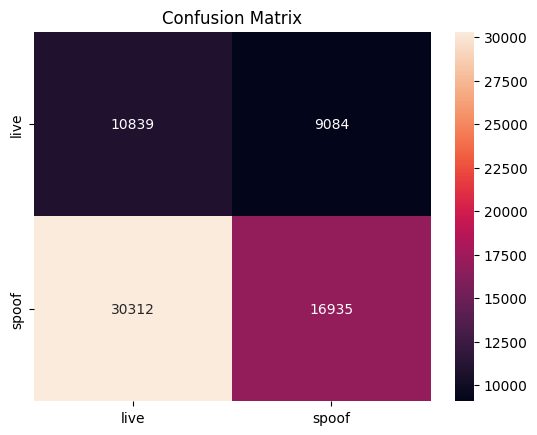

In [10]:

from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

y_true, y_pred = [], []

model.eval()
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        y_true.extend(labels.cpu().numpy())
        y_pred.extend(preds.cpu().numpy())

print(classification_report(y_true, y_pred, target_names=classes))

save_path = "classification_report.csv"
with open(save_path, "w") as f:
    f.write(classification_report(y_true, y_pred, target_names=classes))
print(f"✅ Classification report saved to {save_path}")


cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt="d", xticklabels=classes, yticklabels=classes)
plt.title("Confusion Matrix")
plt.show()


In [ ]:
def predict(image_path, model, transform, device):
    model.eval()
    img = Image.open(image_path).convert("RGB")
    img = transform(img).unsqueeze(0).to(device)
    with torch.no_grad():
        output = model(img)
        _, pred = torch.max(output, 1)
    return classes[pred.item()]


In [ ]:
import torch
import torch.nn as nn
from torchvision import models
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# --- Load CNN-only model ---
cnn_model = models.mobilenet_v2(pretrained=False)
cnn_model.classifier[1] = nn.Linear(cnn_model.last_channel, 2)  # 2 classes

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# Load the checkpoint
checkpoint = torch.load("face_2.pth", map_location=device)

# Load only the model state dictionary
cnn_model.load_state_dict(checkpoint["model_state"])
cnn_model.to(device)
cnn_model.eval()

# --- Evaluate ---
all_labels, all_preds = [], []

with torch.no_grad():
    for inputs, labels in test_loader:  # <- use your test_loader for frames
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = cnn_model(inputs)
        _, preds = torch.max(outputs, 1)
        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())

print("📊 CNN-only Model Results")
print(classification_report(all_labels, all_preds, target_names=["Real", "Attack"]))

# --- Confusion Matrix ---
cm = confusion_matrix(all_labels, all_preds)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Real", "Attack"],
            yticklabels=["Real", "Attack"])
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()


In [11]:
from sklearn.metrics import confusion_matrix

def calculate_spoof_metrics(y_true, y_pred):
    # Labels: 0 = Real, 1 = Attack
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    # BPCER: Real misclassified as Fake (in percentage)
    BPCER = (fn / (tn + fn + 1e-4)) * 100

    # APCER: Fake misclassified as Real (in percentage)
    APCER = (fp / (fp + tp + 1e-4)) * 100

    # ACER: Average Classification Error Rate (in percentage)
    ACER = (APCER + BPCER) / 2

    return {
        "APCER(%)": round(float(APCER) * 100, 2),
        "BPCER(%)": round(float(BPCER) * 100, 2),
        "ACER(%)": round(float(ACER) * 100, 2)
    }

# Example usage:
results = calculate_spoof_metrics(all_labels, all_preds)
print("📊 Anti-Spoofing Metrics:", results)


NameError: name 'all_labels' is not defined